In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv("steps_calories.csv")

In [3]:
print("First five rows of the dataset:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nStatistical summary:")
print(df.describe())

print("\nNumber of rows and columns:")
print(df.shape)

First five rows of the dataset:
   Steps  Calories_Burned
0   8270              328
1   1860               92
2   6390              282
3  14418              550
4   6191              265

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Steps            400 non-null    int64
 1   Calories_Burned  400 non-null    int64
dtypes: int64(2)
memory usage: 6.4 KB
None

Statistical summary:
              Steps  Calories_Burned
count    400.000000       400.000000
mean    8099.972500       324.805000
std     3973.146419       161.836723
min     1064.000000        20.000000
25%     4735.000000       193.750000
50%     7992.000000       320.000000
75%    11639.500000       456.000000
max    14992.000000       786.000000

Number of rows and columns:
(400, 2)


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.dropna(subset=["Steps", "Calories_Burned"])
df = df.drop_duplicates()

print("\nDataset after cleaning:")
print(df.shape)

Missing values:
Steps              0
Calories_Burned    0
dtype: int64

Duplicate rows: 0

Dataset after cleaning:
(400, 2)


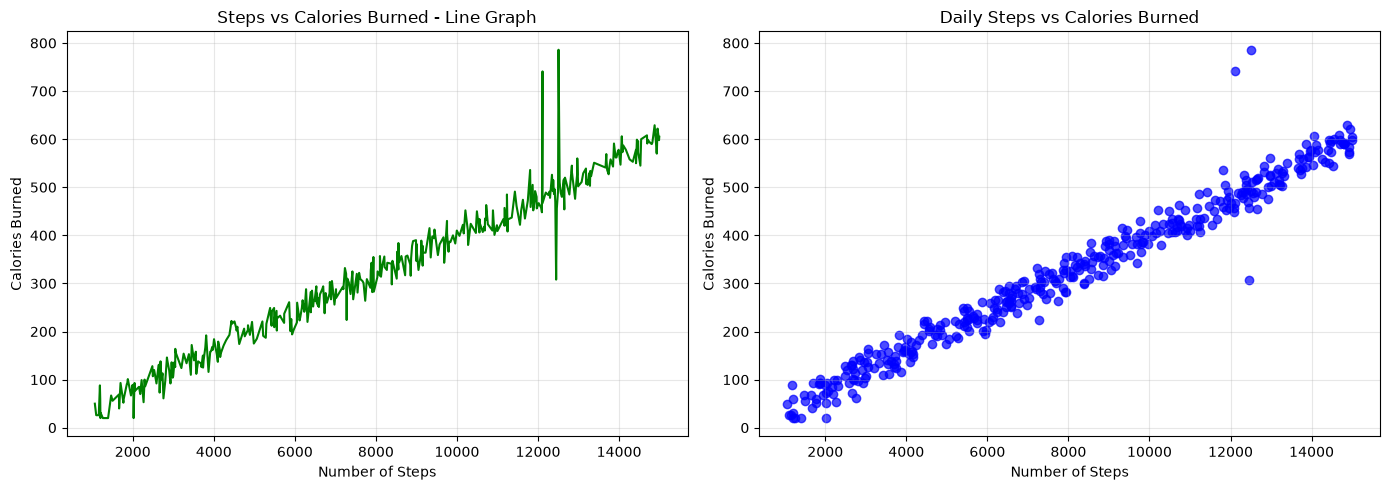

In [5]:
sorted_df = df.sort_values("Steps")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Line graph
axes[0].plot(
    sorted_df["Steps"],
    sorted_df["Calories_Burned"],
    color="green",
    linewidth=1.5
)
axes[0].set_title("Steps vs Calories Burned - Line Graph")
axes[0].set_xlabel("Number of Steps")
axes[0].set_ylabel("Calories Burned")
axes[0].grid(True, alpha=0.3)

# Scatter plot
axes[1].scatter(
    df["Steps"],
    df["Calories_Burned"],
    color="blue",
    alpha=0.7
)
axes[1].set_title("Daily Steps vs Calories Burned")
axes[1].set_xlabel("Number of Steps")
axes[1].set_ylabel("Calories Burned")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

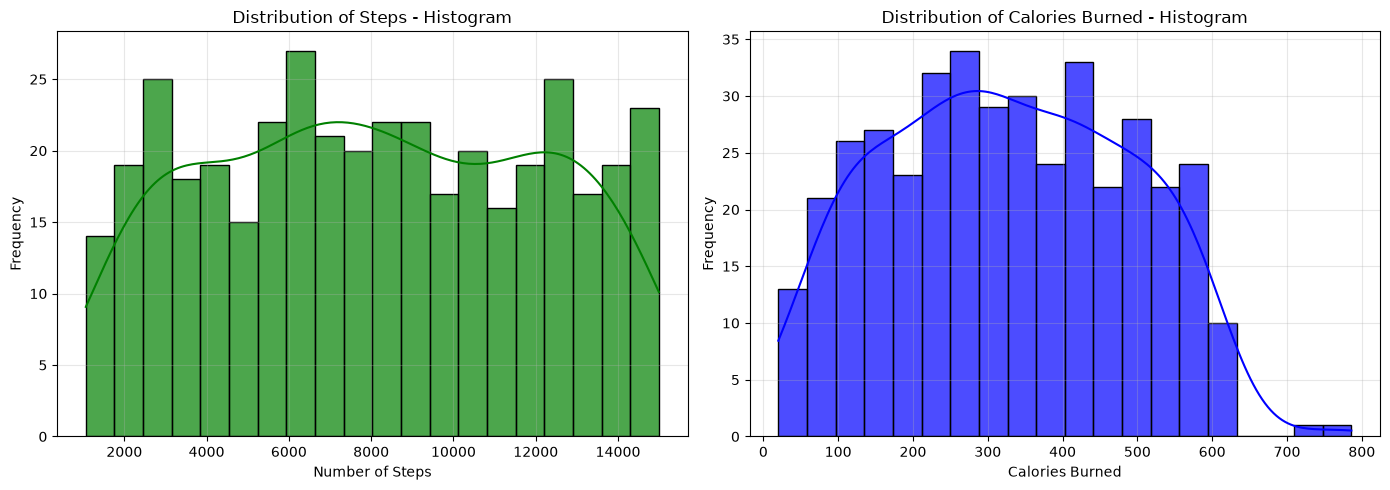

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram for Steps
sns.histplot(
    data=df,
    x="Steps",
    bins=20,
    color="green",
    edgecolor="black",
    alpha=0.7,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Steps - Histogram")
axes[0].set_xlabel("Number of Steps")
axes[0].set_ylabel("Frequency")
axes[0].grid(True, alpha=0.3)

# Histogram for Calories Burned
sns.histplot(
    data=df,
    x="Calories_Burned",
    bins=20,
    color="blue",
    edgecolor="black",
    alpha=0.7,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of Calories Burned - Histogram")
axes[1].set_xlabel("Calories Burned")
axes[1].set_ylabel("Frequency")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

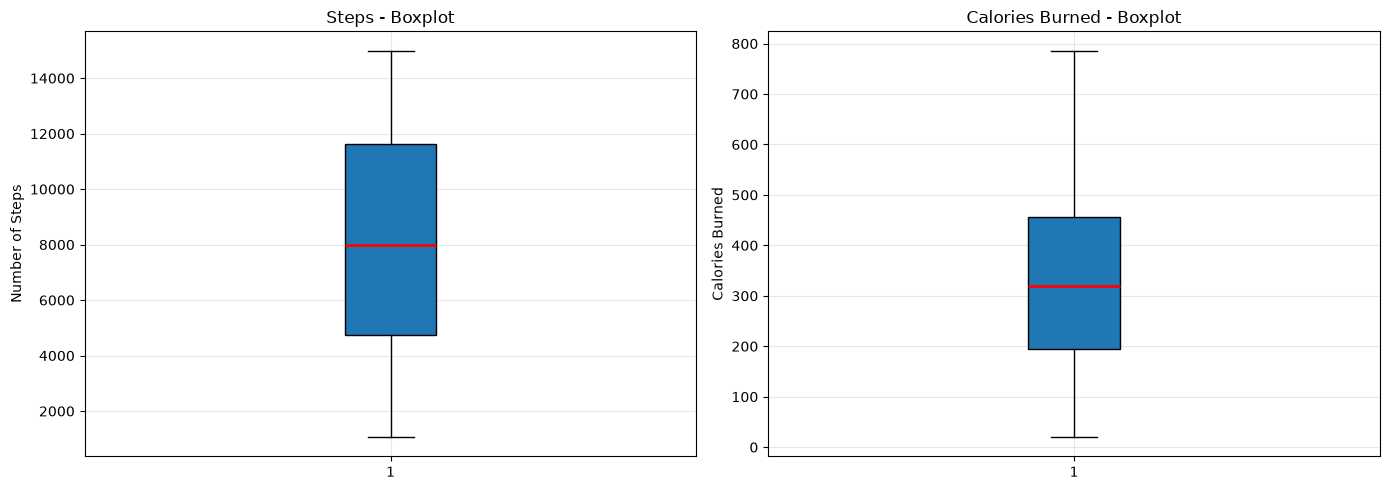

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot for Steps
axes[0].boxplot(
    df["Steps"],
    patch_artist=True,
    medianprops=dict(color="red", linewidth=2)
)
axes[0].set_title("Steps - Boxplot")
axes[0].set_ylabel("Number of Steps")
axes[0].grid(True, alpha=0.3)

# Boxplot for Calories Burned
axes[1].boxplot(
    df["Calories_Burned"],
    patch_artist=True,
    medianprops=dict(color="red", linewidth=2)
)
axes[1].set_title("Calories Burned - Boxplot")
axes[1].set_ylabel("Calories Burned")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

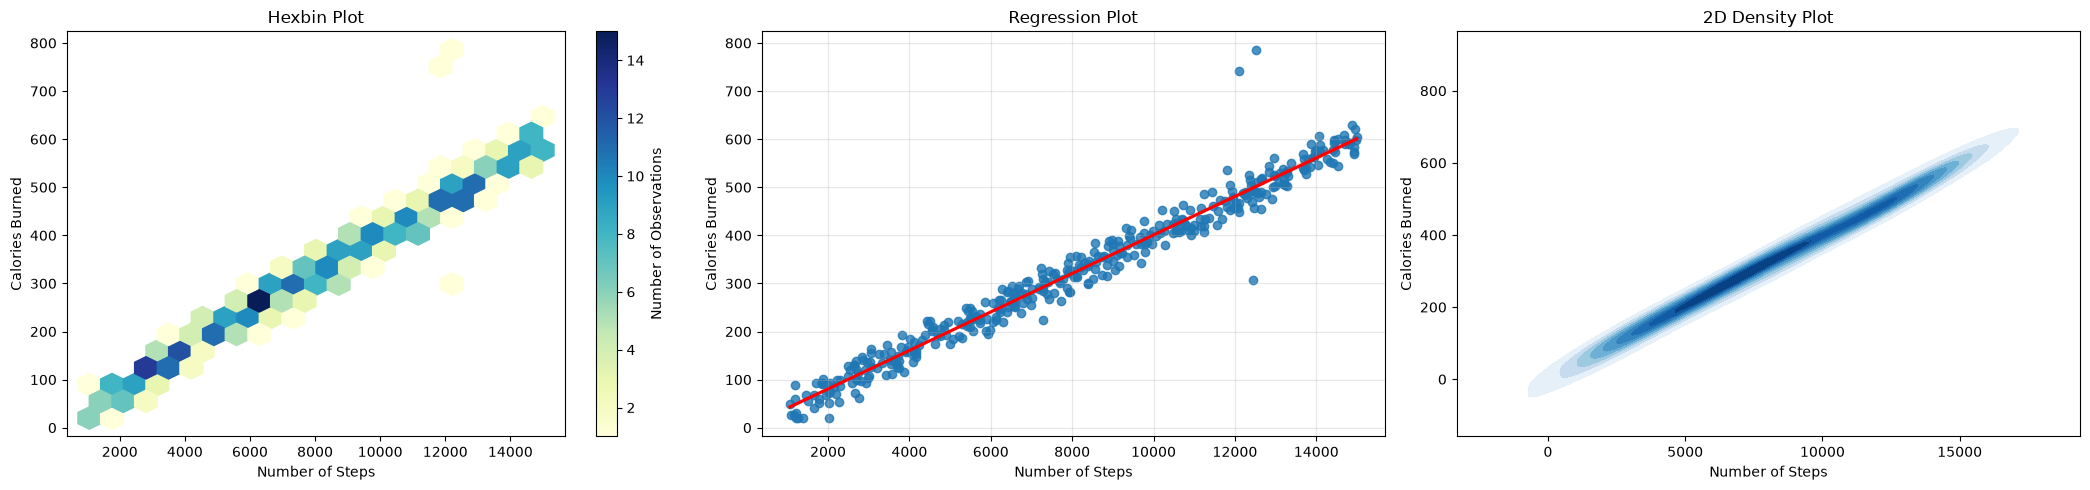

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# 1. Hexbin Plot
hexbin = axes[0].hexbin(
    df["Steps"],
    df["Calories_Burned"],
    gridsize=20,
    cmap="YlGnBu",
    mincnt=1
)
fig.colorbar(hexbin, ax=axes[0], label="Number of Observations")
axes[0].set_title("Hexbin Plot")
axes[0].set_xlabel("Number of Steps")
axes[0].set_ylabel("Calories Burned")

# 2. Regression Plot
sns.regplot(
    data=df,
    x="Steps",
    y="Calories_Burned",
    line_kws={"color": "red"},
    ax=axes[1]
)
axes[1].set_title("Regression Plot")
axes[1].set_xlabel("Number of Steps")
axes[1].set_ylabel("Calories Burned")
axes[1].grid(True, alpha=0.3)

# 3. 2D Density Plot
sns.kdeplot(
    data=df,
    x="Steps",
    y="Calories_Burned",
    fill=True,
    cmap="Blues",
    ax=axes[2]
)
axes[2].set_title("2D Density Plot")
axes[2].set_xlabel("Number of Steps")
axes[2].set_ylabel("Calories Burned")

# Adjust layout
plt.tight_layout()
plt.show()


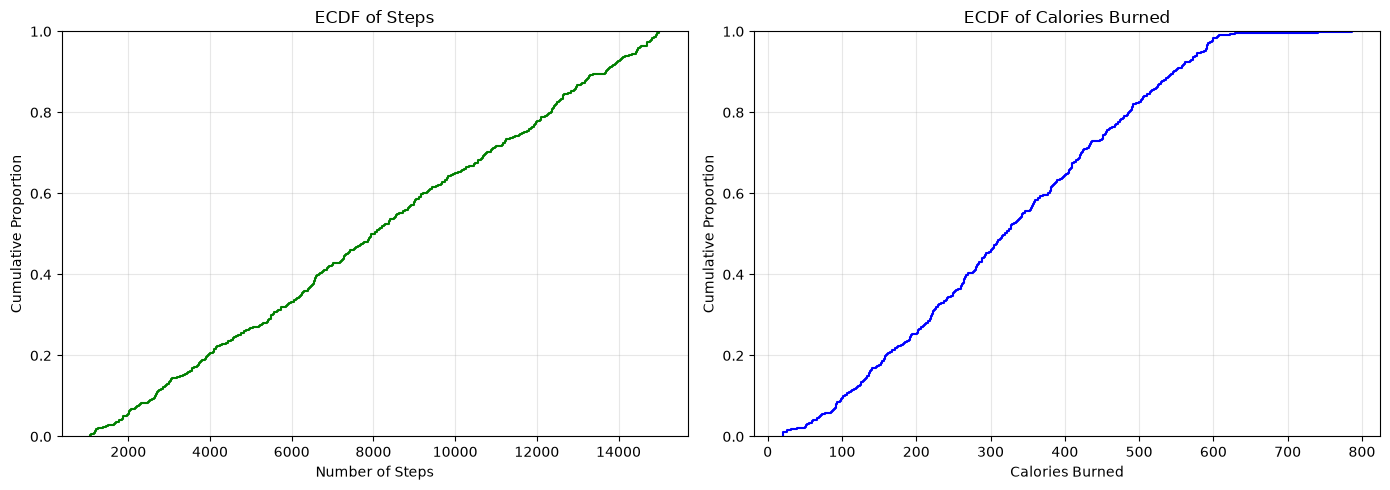

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.ecdfplot(data=df, x="Steps", ax=axes[0], color="green")
axes[0].set_title("ECDF of Steps")
axes[0].set_xlabel("Number of Steps")
axes[0].set_ylabel("Cumulative Proportion")
axes[0].grid(True, alpha=0.3)

sns.ecdfplot(data=df, x="Calories_Burned", ax=axes[1], color="blue")
axes[1].set_title("ECDF of Calories Burned")
axes[1].set_xlabel("Calories Burned")
axes[1].set_ylabel("Cumulative Proportion")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
